# 12 · A Real Corpus: Nine State of the Union Addresses

The capstone used a corpus **we wrote**, so we knew every answer and every defect. Real documents are not like
that: they are long, rhetorical, full of repeated themes and written by different people in different years.
This module repeats the whole method on **nine State of the Union addresses** (1950 to 2006), public-domain
speeches of the United States government, shipped with the course so nothing is downloaded.

Same pipeline, same discipline (dev set, battery, held-out set), different material. The point is to see which
conclusions from the capstone **survive** and which do not.

**You will learn**
1. What changes when the corpus is real: chunk size, metadata, the speaker and the year as part of the question
2. Choosing chunk size and the BM25 weight on a dev set, and why a small battery can disagree with it
3. Why a question about something that was **never said** is the hardest case, and a refusal rule that handles it
4. Fixes that live on the **query side**, because you cannot edit a historical speech (the supervisor loop of module 08 changes shape)
5. Reporting a modest result honestly, with confidence intervals and a held-out set

### Picture: how the real-corpus pipeline differs

The capstone fixed its failures by **editing the documentation**. A speech cannot be edited, so every fix moves
to the side we do own: the question, the retrieval filter and the refusal rule.

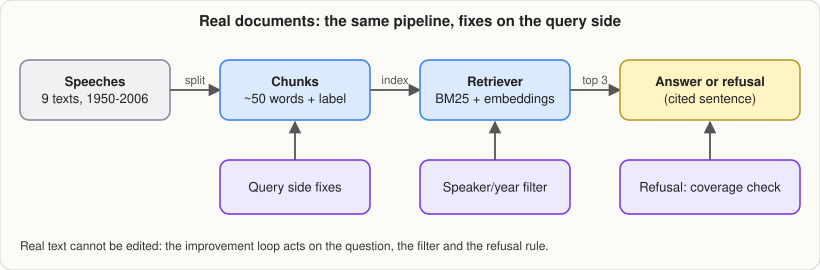

In [1]:
from IPython.display import SVG, display
import html as _h

_COL = {  # fill, stroke  (light cards with dark text: readable in light and dark themes)
    "gold": ("#fff4c2", "#b89d28"), "blue": ("#dbeafe", "#3b82f6"), "green": ("#dcfce7", "#16a34a"),
    "red": ("#fee2e2", "#dc2626"), "grey": ("#f1f1f4", "#8a8aa0"), "violet": ("#ede9fe", "#7c3aed"),
}

def diagram(width, height, items, title=None):
    # items: ("box", x, y, w, h, "text\nmore text", colour) | ("arrow", x1, y1, x2, y2, "label") |
    #        ("text", x, y, "text", size, "start|middle|end") | ("note", x, y, w, h, "text")
    out = [f'<svg xmlns="http://www.w3.org/2000/svg" viewBox="0 0 {width} {height}" width="100%" '
           f'font-family="Helvetica, Arial, sans-serif">',
           '<defs><marker id="ah" viewBox="0 0 10 10" refX="9" refY="5" markerWidth="7" markerHeight="7" '
           'orient="auto-start-reverse"><path d="M0,0 L10,5 L0,10 z" fill="#555"/></marker></defs>',
           f'<rect width="{width}" height="{height}" rx="12" fill="#fbfbf8" stroke="#d8d8cf"/>']
    if title:
        out.append(f'<text x="{width / 2}" y="26" text-anchor="middle" font-size="15" font-weight="700" fill="#222">{_h.escape(title)}</text>')
    for it in items:
        kind = it[0]
        if kind == "box":
            _, x, y, w, h, text, col = it
            fill, stroke = _COL[col]
            out.append(f'<rect x="{x}" y="{y}" width="{w}" height="{h}" rx="9" fill="{fill}" stroke="{stroke}" stroke-width="1.6"/>')
            lines = text.split("\n")
            y0 = y + h / 2 - (len(lines) - 1) * 8.5 + 4.5
            for k, ln in enumerate(lines):
                bold = ' font-weight="700"' if k == 0 and len(lines) > 1 else ""
                out.append(f'<text x="{x + w / 2}" y="{y0 + k * 17}" text-anchor="middle" font-size="13" fill="#222"{bold}>{_h.escape(ln)}</text>')
        elif kind == "arrow":
            _, x1, y1, x2, y2, label = it
            out.append(f'<line x1="{x1}" y1="{y1}" x2="{x2}" y2="{y2}" stroke="#555" stroke-width="1.8" marker-end="url(#ah)"/>')
            if label:
                out.append(f'<text x="{(x1 + x2) / 2}" y="{(y1 + y2) / 2 - 6}" text-anchor="middle" font-size="11.5" fill="#555">{_h.escape(label)}</text>')
        elif kind == "text":
            _, x, y, text, size, anchor = it
            for k, ln in enumerate(text.split("\n")):
                out.append(f'<text x="{x}" y="{y + k * (size + 4)}" text-anchor="{anchor}" font-size="{size}" fill="#333">{_h.escape(ln)}</text>')
        elif kind == "note":
            _, x, y, w, h, text = it
            out.append(f'<rect x="{x}" y="{y}" width="{w}" height="{h}" rx="6" fill="none" stroke="#b89d28" stroke-dasharray="5 4"/>')
            for k, ln in enumerate(text.split("\n")):
                out.append(f'<text x="{x + 10}" y="{y + 20 + k * 16}" font-size="12" fill="#444">{_h.escape(ln)}</text>')
    out.append("</svg>")
    display(SVG("".join(out)))

diagram(820, 270, [
    ("box", 20, 60, 150, 60, "Speeches\n9 texts, 1950-2006", "grey"),
    ("arrow", 170, 90, 220, 90, "split"),
    ("box", 220, 60, 150, 60, "Chunks\n~50 words + label", "blue"),
    ("arrow", 370, 90, 420, 90, "index"),
    ("box", 420, 60, 150, 60, "Retriever\nBM25 + embeddings", "blue"),
    ("arrow", 570, 90, 620, 90, "top 3"),
    ("box", 620, 60, 180, 60, "Answer or refusal\n(cited sentence)", "gold"),
    ("box", 220, 160, 150, 54, "Query side fixes", "violet"),
    ("arrow", 295, 160, 295, 122, ""),
    ("box", 420, 160, 150, 54, "Speaker/year filter", "violet"),
    ("arrow", 495, 160, 495, 122, ""),
    ("box", 620, 160, 180, 54, "Refusal: coverage check", "violet"),
    ("arrow", 710, 160, 710, 122, ""),
    ("text", 20, 250, "Real text cannot be edited: the improvement loop acts on the question, the filter and the refusal rule.", 12, "start"),
], title="Real documents: the same pipeline, fixes on the query side")

## 1. The corpus

Nine addresses, one per era: Truman (1950), Eisenhower (1957), Kennedy (1962), Johnson (1966), Nixon (1974),
Reagan (1982), Clinton (1994) and G. W. Bush (2002 and 2006). They come from the [`state_union` corpus](https://www.nltk.org/nltk_data/) distributed
with NLTK, which reproduces the texts of [The American Presidency Project](https://www.presidency.ucsb.edu/); as works of the federal government they are in the public domain.

We split each speech into **chunks** of about 50 words made of whole sentences, and put a label in front of every
chunk (`1974 address by President Nixon.`). Whether the label helps is measured in section 3, and the answer is less clear-cut than we would like.

In [2]:
import os, re, math, glob, urllib.request
from collections import Counter, defaultdict
import numpy as np
import matplotlib.pyplot as plt
from sentence_transformers import SentenceTransformer

SPEECHES = ["1950-Truman", "1957-Eisenhower", "1962-Kennedy", "1966-Johnson", "1974-Nixon",
            "1982-Reagan", "1994-Clinton", "2002-GWBush", "2006-GWBush"]
DATA = next((p for p in ("data/sotu", "../data/sotu") if os.path.isdir(p)), "data/sotu")
os.makedirs(DATA, exist_ok=True)
for name in SPEECHES:                       # only needed if you downloaded this notebook on its own
    path = f"{DATA}/{name}.txt"
    if not os.path.exists(path):
        urllib.request.urlretrieve(f"https://raw.githubusercontent.com/fborbon/academy/main/rag-systems/data/sotu/{name}.txt", path)

def read_sentences(name):
    paras = [p.strip() for p in open(f"{DATA}/{name}.txt", encoding="utf-8").read().split("\n")
             if len(p.strip()) > 60 and not p.strip().startswith("Note:") and not p.strip().isupper()]
    return [s for p in paras for s in re.split(r"(?<=[.!?])\s+", p) if s]

def make_chunks(target_words):
    # consecutive whole sentences until the chunk reaches target_words; the speech, the year and the speaker travel with it
    out = []
    for name in SPEECHES:
        year, pres = name.split("-")
        cur, n, k = [], 0, 1
        for s in read_sentences(name):
            cur.append(s); n += len(s.split())
            if n >= target_words:
                out.append(dict(id=f"{year}-{k:03d}", year=year, pres=pres, text=" ".join(cur))); cur, n, k = [], 0, k + 1
        if cur:
            out.append(dict(id=f"{year}-{k:03d}", year=year, pres=pres, text=" ".join(cur)))
    return out

chunks = make_chunks(50)
print(f"{len(SPEECHES)} speeches, {sum(len(read_sentences(n)) for n in SPEECHES)} sentences, {len(chunks)} chunks of about 50 words")
print(f"{'speech':<18}{'words':>8}{'chunks':>8}")
for n in SPEECHES:
    print(f"{n:<18}{sum(len(s.split()) for s in read_sentences(n)):>8}{sum(c['year'] == n[:4] for c in chunks):>8}")

/home/patito/.local/lib/python3.12/site-packages/matplotlib/projections/__init__.py:63: UserWarning: Unable to import Axes3D. This may be due to multiple versions of Matplotlib being installed (e.g. as a system package and as a pip package). As a result, the 3D projection is not available.
  warnings.warn("Unable to import Axes3D. This may be due to multiple versions of "
/home/patito/.local/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


9 speeches, 2399 sentences, 763 chunks of about 50 words
speech               words  chunks
1950-Truman           5122      81
1957-Eisenhower       4097      65
1962-Kennedy          6629     102
1966-Johnson          5397      84
1974-Nixon            5199      80
1982-Reagan           5202      80
1994-Clinton          7382     117
2002-GWBush           3941      63
2006-GWBush           5576      91


## 2. Three sets of questions, written to be checked automatically

We cannot ask a person to grade every answer, so each question carries a **key**: a short phrase that appears in
the sentence that answers it, in one named speech. An answer is **correct** when it cites a chunk of that speech
**and** its sentence contains the key. An unanswerable question is answered correctly only by a refusal.

* **dev set (18):** used only to choose chunk size, BM25 weight and the refusal rule. It has four unanswerable questions.
* **battery (28):** the questions we report on, 22 answerable and 6 unanswerable, written before the fixes.
* **held-out set (16):** written **after** the fixes were designed, as in module 07, to test whether they generalise.

Question types: `direct` (words close to the text), `paraphrase` (different words), `who` (asks for the speaker or year)
and `trap` (a second speech says something similar). The unanswerable questions are the dangerous ones: the topic often
appears in **another** speech, or nearby in the same one.

In [3]:
# (id, question, speech year, key phrase in the answering sentence, type); year None = nothing in the corpus answers it
DEV = [
 ("d01", "How many fewer pages did the register of regulations have in 1981 than in 1980?", "1982", "23,000 fewer pages", "direct"),
 ("d02", "How many reservists were called up for service?", "1962", "155,000 members", "paraphrase"),
 ("d03", "By how much will the federal workforce shrink?", "1994", "252,000 people", "paraphrase"),
 ("d04", "What does the military campaign cost each day?", "2002", "$30 million a day", "paraphrase"),
 ("d05", "How many people of the post-war generation are about to turn sixty?", "2006", "78 million baby boomers", "paraphrase"),
 ("d06", "Has the income of the average family grown over the last half century?", "1950", "buying power has doubled", "paraphrase"),
 ("d07", "How many troops are in Vietnam tonight?", "1966", "190,000 men", "direct"),
 ("d08", "What share of the budget did defense take in 1969?", "1974", "44 percent in 1969", "direct"),
 ("d09", "How much has been committed to rebuild New Orleans?", "2006", "$85 billion", "direct"),
 ("d10", "How many people is the administration serving?", "1957", "170 million people", "direct"),
 ("d11", "How many Americans lack any health insurance at some point in the year?", "1994", "58 million Americans", "paraphrase"),
 ("d12", "How many meals a day does the government subsidize?", "1982", "95 million meals", "direct"),
 ("d13", "Who announced the Advanced Energy Initiative?", "2006", "Advanced Energy Initiative", "who"),
 ("d14", "Which president asked for volunteers to serve the nation?", "2002", "USA Freedom Corps", "who"),
 ("d15", "What did Johnson say about the Internet?", None, None, "unanswerable"),
 ("d16", "What did Eisenhower say about the space shuttle?", None, None, "unanswerable"),
 ("d17", "What did Bush say about the stock market crash?", None, None, "unanswerable"),
 ("d18", "What did Clinton say about September the 11th?", None, None, "unanswerable"),
]
BATTERY = [
 ("b01", "How much did Kennedy propose for the Alliance for Progress?", "1962", "fund of $3 billion", "direct"),
 ("b02", "How fast would the proposed supersonic airplane fly?", "1966", "three times the speed of sound", "direct"),
 ("b03", "How much federal money is planned for energy research over five years?", "1974", "$10 billion in Federal funds", "trap"),
 ("b04", "What increase in clean-energy research was announced?", "2006", "22-percent increase", "paraphrase"),
 ("b05", "What share of Middle East oil imports should be replaced by 2025?", "2006", "75 percent of our oil imports", "direct"),
 ("b06", "How far had interest rates fallen by early 1982?", "1982", "15\\3/4\\ percent", "paraphrase"),
 ("b07", "By when will the states control the federal grant programs?", "1982", "By 1988 the States", "direct"),
 ("b08", "What happened to crime in Houston?", "1994", "crime rate dropped 17 percent", "direct"),
 ("b09", "How much spending did Congress cut?", "1994", "$255 billion in spending", "direct"),
 ("b10", "How much time were Americans asked to give to service?", "2002", "4,000 hours", "paraphrase"),
 ("b11", "How many volunteers will the new corps recruit?", "2002", "200,000 new volunteers", "paraphrase"),
 ("b12", "What was the nation's yearly output in 1950?", "1950", "$255 billion a year", "paraphrase"),
 ("b13", "What did the president propose against road accidents?", "1966", "Highway Safety Act", "paraphrase"),
 ("b14", "What tax incentive was proposed to modernize equipment?", "1962", "8 percent tax credit", "paraphrase"),
 ("b15", "Which housing law is credited with helping low-income families?", "1950", "Housing Act of 1949", "paraphrase"),
 ("b16", "How much child support goes unpaid?", "1994", "$34 billion", "direct"),
 ("b17", "Which president said the Union was at peace with every nation?", "1974", "at peace with every nation", "who"),
 ("b18", "Who proposed the USA Freedom Corps?", "2002", "USA Freedom Corps", "who"),
 ("b19", "Which president announced Project Independence?", "1974", "Project Independence", "who"),
 ("b20", "Who joked that the baby boomers include President Clinton?", "2006", "President Clinton", "who"),
 ("b21", "In which year were the hijackers said to be trained in Afghanistan's camps?", "2002", "trained in Afghanistan", "who"),
 ("b22", "Who said the 17-year rise in crime had been stopped?", "1974", "17-year rise in crime", "who"),
 ("u01", "What did the president say about the Internet?", None, None, "unanswerable"),
 ("u02", "What did Reagan say about the Challenger disaster?", None, None, "unanswerable"),
 ("u03", "What did Kennedy say about Cuba?", None, None, "unanswerable"),
 ("u04", "What did Clinton say about the budget surplus?", None, None, "unanswerable"),
 ("u05", "What did Bush say about Hurricane Katrina?", None, None, "unanswerable"),
 ("u06", "How did the 2010 address describe health care reform?", None, None, "unanswerable"),
]
HELDOUT = [
 ("e01", "How many adults cannot read well enough to function?", "1962", "Eight million adult Americans", "paraphrase"),
 ("e02", "What change did Johnson propose to the term of House members?", "1966", "4-year term for Members of the House", "direct"),
 ("e03", "How many people live in the country, according to the 1974 address?", "1974", "211 million people", "direct"),
 ("e04", "By how many will the federal work force be reduced?", "1982", "75,000", "direct"),
 ("e05", "How many more police officers will be funded?", "1994", "100,000 of them", "paraphrase"),
 ("e06", "What did the president ask Congress to protect for retirement savings?", "2002", "401K and pension plans", "paraphrase"),
 ("e07", "Who was thanked for 24 years of service on the court?", "2006", "Sandra Day O'Connor", "who"),
 ("e08", "How does job creation compare with Japan and the European Union?", "2006", "more than Japan and the European Union combined", "paraphrase"),
 ("e09", "What share of government spending pays for past wars?", "1950", "More than 70 percent", "paraphrase"),
 ("e10", "What happened to farm income in 1961?", "1962", "billion dollar rise in farm income", "direct"),
 ("e11", "How many private peace talks took place in 1965?", "1966", "300 private talks", "direct"),
 ("e12", "How much did the food stamp program grow in fifteen years?", "1982", "16,000 percent", "paraphrase"),
 ("v01", "What did Truman say about television?", None, None, "unanswerable"),
 ("v02", "What did Johnson say about the Berlin Wall?", None, None, "unanswerable"),
 ("v03", "What did Bush say about the housing bubble?", None, None, "unanswerable"),
 ("v04", "What did Reagan say about Gorbachev?", None, None, "unanswerable"),
]
OFF_TOPIC = ["What is the capital of France?", "How do I bake sourdough bread?", "Who won the football match yesterday?", "What is the speed of light?"]

# a key must exist in its speech (and in no other), or the question is unfair
for q in DEV + BATTERY + HELDOUT:
    if q[2]:
        in_speech = [c["id"] for c in chunks if c["year"] == q[2] and q[3] in c["text"]]
        elsewhere = [c["id"] for c in chunks if c["year"] != q[2] and q[3] in c["text"]]
        assert in_speech and not elsewhere, (q[0], in_speech, elsewhere)
for name, S in (("dev", DEV), ("battery", BATTERY), ("held-out", HELDOUT)):
    print(f"{name:<9}{len(S):>3} questions:", dict(Counter(q[4] for q in S)))

dev       18 questions: {'direct': 6, 'paraphrase': 6, 'who': 2, 'unanswerable': 4}
battery   28 questions: {'direct': 7, 'trap': 1, 'paraphrase': 8, 'who': 6, 'unanswerable': 6}
held-out  16 questions: {'paraphrase': 6, 'direct': 5, 'who': 1, 'unanswerable': 4}


## 3. Retrieval: what to measure before building anything

A retriever is good for a question if some chunk containing the key reaches the top of the ranking. Three decisions,
each **chosen on the dev set only**: how big a chunk is, whether the speaker and year are written into the chunk, and
how much BM25 to mix into the embeddings (module 02).

In [4]:
embedder = SentenceTransformer("sentence-transformers/all-MiniLM-L6-v2", device="cpu")
STOP = set("a an and are as at be by can do does for from how i if in is it of on or that the this to what when which who with you my me did was were has have had been will".split())
tokens = lambda text: [w for w in re.findall(r"[a-z0-9]+", text.lower()) if w not in STOP]

class Index:
    # BM25 + embeddings over a list of chunks; label=True writes the year and speaker in front of each chunk
    def __init__(self, chunks, label=True):
        self.chunks = chunks
        self.texts = [(f"{c['year']} address by President {c['pres']}. " if label else "") + c["text"] for c in chunks]
        self.tf = [Counter(tokens(t)) for t in self.texts]
        self.len = np.array([sum(d.values()) for d in self.tf], float)
        df = Counter(w for d in self.tf for w in d)
        n = len(self.texts)
        self.idf = {w: math.log(1 + (n - c + 0.5) / (c + 0.5)) for w, c in df.items()}
        self.emb = embedder.encode(self.texts, normalize_embeddings=True, batch_size=64)
        self.avg = self.len.mean()
    def bm25(self, q):
        s = np.zeros(len(self.texts))
        for w in set(tokens(q)):
            if w in self.idf:
                for i, d in enumerate(self.tf):
                    f = d.get(w, 0)
                    if f:
                        s[i] += self.idf[w] * f * 2.5 / (f + 1.5 * (0.25 + 0.75 * self.len[i] / self.avg))
        return s
    def cosine(self, q):
        return self.emb @ embedder.encode(q, normalize_embeddings=True)
    def fused(self, q, w_bm25):
        tot = np.zeros(len(self.texts))
        for sc, w in ((self.bm25(q), w_bm25), (self.cosine(q), 1.0)):
            for rank, i in enumerate(np.argsort(-sc), 1):
                tot[i] += w / (60 + rank)
        return tot

def retrieval(idx, S, w):
    # hit@1, hit@3, MRR for the answerable questions of S
    ranks = []
    for _, q, year, key, _t in S:
        if year is None:
            continue
        order = list(np.argsort(-idx.fused(q, w)))
        gold = [i for i, c in enumerate(idx.chunks) if c["year"] == year and key in c["text"]]
        ranks.append(min(order.index(g) for g in gold) + 1)
    r = np.array(ranks)
    return (r == 1).mean(), (r <= 3).mean(), (1 / r).mean()

print(f"{'chunk size':<14}{'chunks':>7}   dev hit@1  hit@3   MRR      battery hit@1  hit@3   MRR")
SIZES = {}
for target in (25, 50, 100, 200):
    ch = make_chunks(target); idx_t = Index(ch)
    SIZES[target] = (idx_t, retrieval(idx_t, DEV, 0.5), retrieval(idx_t, BATTERY, 0.5))
    d, b = SIZES[target][1], SIZES[target][2]
    print(f"{target:>3} words{len(ch):>10}      {d[0]:>6.2f} {d[1]:>6.2f} {d[2]:>6.2f}          {b[0]:>6.2f} {b[1]:>6.2f} {b[2]:>6.2f}")
CHUNK_WORDS = max(SIZES, key=lambda t: (SIZES[t][1][2], -t))
print("chosen on the dev set (best MRR):", CHUNK_WORDS, "words")

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 103/103 [00:00<00:00, 2725.64it/s]

chunk size     chunks   dev hit@1  hit@3   MRR      battery hit@1  hit@3   MRR


 25 words      1280        0.64   0.79   0.72            0.73   0.95   0.84


 50 words       763        0.64   0.93   0.79            0.64   0.95   0.80


100 words       434        0.43   0.93   0.68            0.95   0.95   0.97


200 words       232        0.43   0.71   0.60            0.73   0.95   0.85
chosen on the dev set (best MRR): 50 words


The **dev set picks one chunk size and the battery would have picked another**. With 14 and 22 answerable questions
each, a difference of one or two questions flips the ranking: the same warning as module 07, now visible on real text.
We keep the choice made on dev, because choosing on the battery would leak it. The two measurements do agree that
very large chunks (200 words, several topics mixed in one vector) are a poor idea for these speeches.

Next, two more choices, again made on dev: whether the label (speaker and year) goes in front of each chunk, and the BM25 weight.

In [5]:
P = SIZES[CHUNK_WORDS][0]
labelled = P
plain = Index(P.chunks, label=False)
WHO = [q for q in DEV + BATTERY if q[4] == "who"]
print("speaker and year written into the chunk? (BM25 weight 0.5, chunk size", CHUNK_WORDS, ")")
print(f"{'':<18}{'who questions hit@1':>22}{'all dev hit@1':>16}{'all battery hit@1':>20}")
for name, ix in (("no label", plain), ("with label", labelled)):
    print(f"{name:<18}{retrieval(ix, WHO, 0.5)[0]:>22.2f}{retrieval(ix, DEV, 0.5)[0]:>16.2f}{retrieval(ix, BATTERY, 0.5)[0]:>20.2f}")

print("\nBM25 weight (semantic weight = 1) on the DEV set:")
dev_w = {}
for w in (0, 0.25, 0.5, 1, 2):
    dev_w[w] = retrieval(labelled, DEV, w)
    print(f"  weight {w:<5} hit@1 {dev_w[w][0]:.2f}  hit@3 {dev_w[w][1]:.2f}  MRR {dev_w[w][2]:.2f}")
W_BM25 = max(dev_w, key=lambda w: (dev_w[w][2], -w))
print("chosen BM25 weight:", W_BM25)

speaker and year written into the chunk? (BM25 weight 0.5, chunk size 50 )
                     who questions hit@1   all dev hit@1   all battery hit@1


no label                            0.88            0.57                0.77


with label                          0.88            0.64                0.64

BM25 weight (semantic weight = 1) on the DEV set:


  weight 0     hit@1 0.71  hit@3 0.71  MRR 0.76


  weight 0.25  hit@1 0.79  hit@3 1.00  MRR 0.88


  weight 0.5   hit@1 0.64  hit@3 0.93  MRR 0.79


  weight 1     hit@1 0.64  hit@3 0.86  MRR 0.75


  weight 2     hit@1 0.50  hit@3 0.71  MRR 0.64
chosen BM25 weight: 0.25


Three things to read from this table, none of them what a tutorial would tell you:

* **The label helps on dev and hurts on the battery.** On "who" questions it makes no difference at all. Both sets are tiny, so we cannot say it helps; we keep it, as chosen on dev, and we do **not** claim a benefit.
* **Hybrid search does help here**, with a small BM25 weight (0.25). In the capstone the best weight was zero. The right weight depends on the corpus: these speeches are full of numbers and names that BM25 matches exactly. This is the module 02 lesson again, with the opposite sign.
* **The weight must be measured, not remembered.** A rule "hybrid is always better" and a rule "hybrid is never better" are both wrong.

### Picture: one real question through the improved system

The data flow of this module in one example. Follow the question from the left: the filter narrows the search
to the speech the question names, retrieval ranks chunks inside it, a sentence is selected, and the refusal rule
decides whether to answer. The unanswerable question stops at the last box.

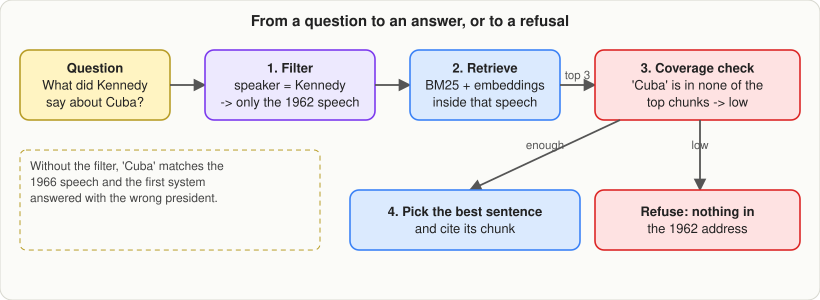

In [6]:
diagram(820, 300, [
    ("box", 20, 50, 150, 70, "Question\nWhat did Kennedy\nsay about Cuba?", "gold"),
    ("arrow", 170, 85, 205, 85, ""),
    ("box", 205, 50, 170, 70, "1. Filter\nspeaker = Kennedy\n-> only the 1962 speech", "violet"),
    ("arrow", 375, 85, 410, 85, ""),
    ("box", 410, 50, 150, 70, "2. Retrieve\nBM25 + embeddings\ninside that speech", "blue"),
    ("arrow", 560, 85, 595, 85, "top 3"),
    ("box", 595, 50, 205, 70, "3. Coverage check\n'Cuba' is in none of the\ntop chunks -> low", "red"),
    ("arrow", 700, 120, 700, 190, "low"),
    ("box", 595, 190, 205, 60, "Refuse: nothing in\nthe 1962 address", "red"),
    ("arrow", 620, 120, 470, 190, "enough"),
    ("box", 350, 190, 230, 60, "4. Pick the best sentence\nand cite its chunk", "blue"),
    ("note", 20, 150, 300, 100, "Without the filter, 'Cuba' matches the\n1966 speech and the first system\nanswered with the wrong president."),
], title="From a question to an answer, or to a refusal")

## 4. The first system: the capstone method, unchanged

Same design as the capstone: retrieve, refuse when the best cosine is below a threshold, answer with the sentence of the
top chunk closest to the question. The threshold comes from the dev answerable questions and the off-topic ones.

In [7]:
SENT = {}                                                    # sentence embeddings cached per chunk
def sentences_of(i):
    if i not in SENT:
        s = [x for x in re.split(r"(?<=[.!?])\s+", P.chunks[i]["text"]) if x]
        SENT[i] = (s, embedder.encode(s, normalize_embeddings=True))
    return SENT[i]

dev_top = [P.cosine(q[1]).max() for q in DEV if q[2]]
off_top = [P.cosine(q).max() for q in OFF_TOPIC]
T_COS = (max(off_top) + min(dev_top)) / 2
print(f"top cosine: answerable dev {min(dev_top):.2f} to {max(dev_top):.2f}; off-topic {min(off_top):.2f} to {max(off_top):.2f}  ->  refuse below {T_COS:.2f}")

def answer_v1(q):
    cos = P.cosine(q)
    if cos.max() < T_COS:
        return "refuse", None, None
    top = int(np.argmax(P.fused(q, W_BM25)))
    s, e = sentences_of(top)
    return "answer", P.chunks[top]["id"], s[int(np.argmax(e @ embedder.encode(q, normalize_embeddings=True)))]

def grade(q, res):
    kind, cid, sent = res
    if q[2] is None:
        return "ok" if kind == "refuse" else "wrong"
    if kind == "refuse":
        return "missed"
    return "ok" if cid[:4] == q[2] and q[3] in sent else "wrong"

def report(system, S):
    res = [(q, grade(q, system(q[1]))) for q in S]
    by = defaultdict(lambda: [0, 0])
    for q, g in res:
        by[q[4]][1] += 1; by[q[4]][0] += g == "ok"
    return sum(g == "ok" for _, g in res), len(S), dict(by), res

for name, S in (("dev", DEV), ("battery", BATTERY)):
    ok, n, by, res = report(answer_v1, S)
    print(f"{name:<8} correct {ok:>2} of {n}   " + "  ".join(f"{t} {a}/{b}" for t, (a, b) in by.items()))

top cosine: answerable dev 0.42 to 0.73; off-topic 0.16 to 0.22  ->  refuse below 0.32


dev      correct  7 of 18   direct 4/6  paraphrase 1/6  who 2/2  unanswerable 0/4


battery  correct 14 of 28   direct 5/7  trap 1/1  paraphrase 3/8  who 5/6  unanswerable 0/6


The first system gets about half of the battery right, far below the capstone's 75%. It fails in two different ways, and
they need different fixes:

* **Unanswerable questions are never refused.** The topic of "what did Reagan say about the Challenger disaster" is close to many sentences
  of the corpus, so the top cosine is as high as for a real question. A threshold on similarity cannot separate them.
* **Right speech, wrong sentence, or wrong speech.** Several questions return a chunk from another year, or the right chunk with a sentence that only
  echoes the question's words ("How many men who listen to me tonight...").

In [8]:
ok, n, by, res = report(answer_v1, BATTERY)
print("battery failures of the first system:")
for q, g in res:
    if g != "ok":
        kind, cid, sent = answer_v1(q[1])
        print(f"  {q[0]} [{g}] {q[1][:62]}\n        -> {cid} {(sent or '')[:78]}")

battery failures of the first system:


  b01 [wrong] How much did Kennedy propose for the Alliance for Progress?
        -> 1962-065 The Alliance for Progress is being rapidly transformed from proposal to progra
  b05 [wrong] What share of Middle East oil imports should be replaced by 20
        -> 1957-058 But these people, whose economic strength is largely dependent on free and uni
  b06 [wrong] How far had interest rates fallen by early 1982?
        -> 1982-008 Interest rates reached a staggering 21\1/2\ percent.


  b10 [wrong] How much time were Americans asked to give to service?
        -> 1994-070 The American people provide those of us in Government service with terrific he
  b12 [wrong] What was the nation's yearly output in 1950?
        -> 1950-040 If our productive power continues to increase at the same rate as it has incre
  b14 [wrong] What tax incentive was proposed to modernize equipment?
        -> 1982-039 While meeting all these needs, we intend to plug unwarranted tax loopholes and


  b15 [wrong] Which housing law is credited with helping low-income families
        -> 1950-055 To aid the middle-income families, I recommend that the Congress enact new leg
  b17 [wrong] Which president said the Union was at peace with every nation?
        -> 1966-072 We have carried our quest for peace to many nations and peoples because we sha
  u01 [wrong] What did the president say about the Internet?
        -> 1994-039 And without blinking an eye, she looked at 40 Governors, and she said, "When m


  u02 [wrong] What did Reagan say about the Challenger disaster?
        -> 1982-012 There were also pessimistic predictions about the relationship between our adm
  u03 [wrong] What did Kennedy say about Cuba?
        -> 1966-045 In this pursuit we have defended against Communist aggression--in Korea under 
  u04 [wrong] What did Clinton say about the budget surplus?
        -> 1994-016 We froze domestic spending and used honest budget numbers.


  u05 [wrong] What did Bush say about Hurricane Katrina?
        -> 2002-047 (Applause.) The American people have responded magnificently, with courage and
  u06 [wrong] How did the 2010 address describe health care reform?
        -> 1994-067 Now, in the coming months I hope very much to work with both Democrats and Rep


## 5. Three fixes that live on the query side

A supervisor reading these failures (module 08) would flag them and ask a person to fix the documentation. Here the
documentation is a historical record, so the fixes go to the system around it. Each one is a **general** rule, not a patch for
one question, and each has a parameter that we choose on the **dev set**:

1. **Speaker and year filter.** If the question names a president or a year, search only the matching speeches. A year with no speech (2010) means there is nothing to find.
2. **Coverage check for refusal.** For an answerable question, nearly all of its content words (lightly stemmed) appear in the best chunks. For "Challenger", "Katrina" or "Internet" they do not.
3. **Quantity boost.** For "how many", "how much" or "what share" questions, prefer the sentence that contains a number.

In [9]:
PRES = {"truman": {"1950"}, "eisenhower": {"1957"}, "kennedy": {"1962"}, "johnson": {"1966"}, "nixon": {"1974"},
        "reagan": {"1982"}, "clinton": {"1994"}, "bush": {"2002", "2006"}}
ALL_YEARS = set(c["year"] for c in P.chunks)
GENERIC = set("president said say address speech tell tonight states united american americans year years much many".split())
QTY = re.compile(r"\b(how many|how much|what share|how far|how fast|how long|what increase)\b", re.I)

def stem(w):
    for suf in ("ing", "ed", "es", "s"):
        if w.endswith(suf) and len(w) - len(suf) >= 4:
            return w[:-len(suf)]
    return w

def allowed_speeches(q):
    named = [y for n, ys in PRES.items() if n in q.lower() for y in ys]
    years = set(re.findall(r"\b(19[4-9]\d|20[01]\d)\b", q))
    allowed = set(named) if named else set(ALL_YEARS)
    return allowed & years if years else allowed                # empty set: the question asks about a year we do not have

def coverage(q, chunk_ids):
    words = [stem(w) for w in set(tokens(q)) if w not in GENERIC and w not in PRES and not w.isdigit()]
    if not words:
        return 1.0
    seen = set(stem(w) for i in chunk_ids for w in tokens(P.chunks[i]["text"]))
    return sum(w in seen for w in words) / len(words)

def make_system(cov, boost, use_filter=True, k=3):
    def system(q):
        allowed = allowed_speeches(q) if use_filter else ALL_YEARS
        if not allowed:
            return "refuse", None, None
        sc = P.fused(q, W_BM25)
        for i, c in enumerate(P.chunks):
            if c["year"] not in allowed:
                sc[i] = -1
        order = list(np.argsort(-sc))[:k]
        if cov and coverage(q, order) < cov:
            return "refuse", None, None
        cand = [(i, s, e) for i in order for s, e in zip(*sentences_of(i))]
        sims = np.array([c[2] @ embedder.encode(q, normalize_embeddings=True) for c in cand])
        if boost and QTY.search(q):
            sims = sims + boost * np.array([bool(re.search(r"\d|\$|percent|million|billion", c[1])) for c in cand])
        i, s, _ = cand[int(np.argmax(sims))]
        return "answer", P.chunks[i]["id"], s
    return system

print(f"{'coverage':>9}{'boost':>7}   dev correct (of {len(DEV)})")
grid = {}
for cov in (0, 0.3, 0.4, 0.5, 0.6, 0.7):
    for boost in (0, 0.1, 0.2):
        grid[(cov, boost)] = report(make_system(cov, boost), DEV)[0]
        print(f"{cov:>9}{boost:>7}   {grid[(cov, boost)]:>3}")
COV, BOOST = max(grid, key=lambda k: (grid[k], k[0], -k[1]))
print("chosen on the dev set:", dict(coverage=COV, boost=BOOST))

 coverage  boost   dev correct (of 18)


        0      0     7


        0    0.1     8


        0    0.2     8


      0.3      0    10


      0.3    0.1    11


... (9 outputs left out)

      0.6    0.2    10


      0.7      0     9


      0.7    0.1     9


      0.7    0.2     9
chosen on the dev set: {'coverage': 0.5, 'boost': 0.1}


## 6. Before and after, on the battery and on the held-out set

The held-out questions were written after the fixes were designed and never used to choose any parameter. The
bootstrap interval (module 07) tells us how much of each change could be luck at this size.

set        questions  first system  improved   change   95% interval of the change


dev               18          0.39      0.67    +0.28   [-0.06, +0.61]


battery           28          0.50      0.68    +0.18   [-0.04, +0.39]


held-out          16          0.44      0.62    +0.19   [-0.06, +0.44]


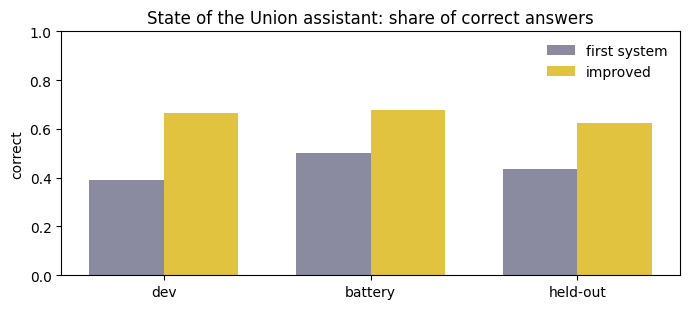

In [10]:
rng = np.random.default_rng(0)
def boot_diff(a, b, n=4000):
    # a, b: per-question 0/1 correctness for the same questions; the interval of mean(b) - mean(a)
    a, b = np.array(a, float), np.array(b, float)
    d = [(b[s] - a[s]).mean() for s in (rng.integers(0, len(a), len(a)) for _ in range(n))]
    return np.percentile(d, [2.5, 97.5])

v1, v2 = answer_v1, make_system(COV, BOOST)
rows = {}
print(f"{'set':<10}{'questions':>10}{'first system':>14}{'improved':>10}{'change':>9}   95% interval of the change")
for name, S in (("dev", DEV), ("battery", BATTERY), ("held-out", HELDOUT)):
    a = [g == "ok" for _, g in report(v1, S)[3]]
    b = [g == "ok" for _, g in report(v2, S)[3]]
    lo, hi = boot_diff(a, b)
    rows[name] = (np.mean(a), np.mean(b))
    print(f"{name:<10}{len(S):>10}{np.mean(a):>14.2f}{np.mean(b):>10.2f}{np.mean(b) - np.mean(a):>+9.2f}   [{lo:+.2f}, {hi:+.2f}]")

fig, ax = plt.subplots(figsize=(7, 3.2))
x = np.arange(3)
ax.bar(x - 0.18, [rows[k][0] for k in rows], 0.36, label="first system", color="#8a8aa0")
ax.bar(x + 0.18, [rows[k][1] for k in rows], 0.36, label="improved", color="#E1C340")
ax.set_xticks(x); ax.set_xticklabels(list(rows)); ax.set_ylim(0, 1); ax.set_ylabel("correct"); ax.legend(frameon=False)
ax.set_title("State of the Union assistant: share of correct answers")
plt.tight_layout(); plt.show()

In [11]:
ok, n, by, res = report(v2, BATTERY)
print("improved system, battery:", ok, "of", n, " ", "  ".join(f"{t} {a}/{b}" for t, (a, b) in by.items()))
for q, g in res:
    if q[2] is None and g != "ok":
        print("  an unanswerable question that was still answered:", q[0], q[1], "->", v2(q[1])[1])
ok, n, by, res = report(v2, HELDOUT)
print("improved system, held-out:", ok, "of", n, " ", "  ".join(f"{t} {a}/{b}" for t, (a, b) in by.items()))
print("\nwhat still fails on the held-out set:")
for q, g in res:
    if g != "ok":
        kind, cid, sent = v2(q[1])
        print(f"  {q[0]} [{g}] {q[1][:60]}\n        -> {cid} {(sent or '')[:78]}")

improved system, battery: 19 of 28   direct 6/7  trap 1/1  paraphrase 3/8  who 4/6  unanswerable 5/6


  an unanswerable question that was still answered: u01 What did the president say about the Internet? -> 2006-042


improved system, held-out: 10 of 16   paraphrase 4/6  direct 2/5  who 1/1  unanswerable 3/4

what still fails on the held-out set:
  e01 [missed] How many adults cannot read well enough to function?
        -> None 


  e03 [wrong] How many people live in the country, according to the 1974 a
        -> 1974-079 But my colleagues, this I believe: With the help of God, who has blessed this 
  e05 [wrong] How many more police officers will be funded?
        -> 1974-057 We have cut our military manpower over the past 5 years by more than a third, 
  e10 [missed] What happened to farm income in 1961?
        -> None 
  e11 [missed] How many private peace talks took place in 1965?
        -> None 


  v04 [wrong] What did Reagan say about Gorbachev?
        -> 1982-067 There must be a real incentive for the Soviets to take these talks seriously.


## 7. What this corpus taught that the capstone could not

Results, in the order of how much we can trust them:

* **Refusing what was never said is the real gain.** Unanswerable questions went from 0 of 6 on the battery to 5 of 6, and from 0 of 4 to 3 of 4 on held-out questions the fixes never saw. This improvement is large and it generalised. A similarity threshold alone could not do it, because the topic of an unanswered question is usually close to something that **was** said, in another speech or a nearby sentence.
* **The one unanswerable question that still gets an answer shows a weakness of the rule.** "What did the president say about the Internet?" has only two content words left after the generic ones, and the filler word "about" is found in every chunk, so coverage is 50%, exactly at the threshold. A list of generic words grows with every failure; an IDF weight on the words would be the principled fix (exercise 3).
* **The overall improvement is plausible but not proven.** Correct answers rose from 0.50 to 0.68 on the battery and from 0.44 to 0.62 on held-out questions, but every 95% interval includes zero. With 28 and 16 questions that is the best we can say, and module 07 already computed how many questions it would take to be sure.
* **Real text is much harder than a text you wrote.** The first system scored 0.75 on the capstone corpus and 0.50 here with the same method. Long rhetorical documents, a retriever that mixes eras, and answers buried in sentences that echo the question all cost accuracy. A good score on your own test corpus is not evidence about real documents.
* **The fixes cost recall.** The coverage check refuses some answerable questions whose wording is far from the text ("How many private peace talks took place in 1965?"). Every refusal rule trades wrong answers for missed ones, and this one was tuned on 14 answerable questions.

**What changes in the improvement loop.** The capstone repaired the documentation. Here the supervisor can still flag the failure and a person can still read the flagged cases, but the fix goes to the query side: a filter, a refusal rule, a ranking preference. Those fixes are general, so they transferred to new questions; a patch written for one failing question would not have.

In [12]:
print(f"{'':<34}{'capstone (Thermio)':>22}{'real speeches':>16}")
print(f"{'documents you can edit':<34}{'yes':>22}{'no':>16}")
print(f"{'passages':<34}{25:>22}{len(P.chunks):>16}")
print(f"{'first system, correct on battery':<34}{'0.75':>22}{rows['battery'][0]:>16.2f}")
print(f"{'after improvements, battery':<34}{'0.96':>22}{rows['battery'][1]:>16.2f}")
print(f"{'after improvements, held-out':<34}{'-':>22}{rows['held-out'][1]:>16.2f}")

                                      capstone (Thermio)   real speeches
documents you can edit                               yes              no
passages                                              25             763
first system, correct on battery                    0.75            0.50
after improvements, battery                         0.96            0.68
after improvements, held-out                           -            0.62


## Exercises

1. Change `CHUNK_WORDS` to the value the **battery** prefers and rerun section 5. Does the conclusion about the fixes change? Why is choosing on the battery a mistake even when it gives a nicer number?
2. Add a speech (any other year of the `state_union` corpus is in the NLTK data, or use your own text) and write six questions with keys. Does the speaker filter still work for a president who gave several addresses?
3. The coverage check refuses on missing words. Find an answerable question that it wrongly refuses, and propose a cheaper fix than lowering the threshold. Then do the opposite for the question about the Internet: weight each word by its IDF instead of counting words, and see whether the filler word \"about\" stops mattering.
4. Replace the sentence selector with a model call (the optional cell pattern of module 04) and measure, with the same battery, whether the quantity boost is still needed.
5. Write ten new unanswerable questions about topics that **do** appear in another speech. How many does the improved system refuse? What would a supervisor need in order to catch the rest?